# Customer Churn Prediction & Retention Analysis

## Project Overview
This project develops a machine learning system to predict whether a customer is likely to leave a subscription-based service.

It also analyzes customer demographics, service usage, billing information, and contract details to identify factors associated with customer churn.

## Objectives
- Clean and preprocess customer data.
- Perform Exploratory Data Analysis (EDA).
- Apply feature engineering and categorical encoding.
- Train machine learning classification models.
- Evaluate model performance.
- Identify important factors associated with customer churn.
- Suggest practical customer retention strategies.

## Technologies Used
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn and Jupyter Notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/Telco-Customer-Churn.csv")

# Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [3]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Missing values
print("Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# Unique customer IDs
print("Unique Customers:", df["customerID"].nunique())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0
Unique Customers: 7043


In [5]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 11


In [6]:
# Fill missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [7]:
# Check cleaned dataset
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
df.head()

Dataset Shape: (7043, 21)

Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


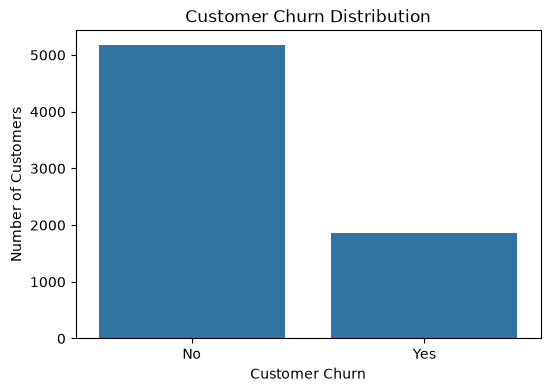

In [8]:
# Count customers who stayed and left
print(df["Churn"].value_counts())

# Calculate percentage
print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

# Visualize churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.show()

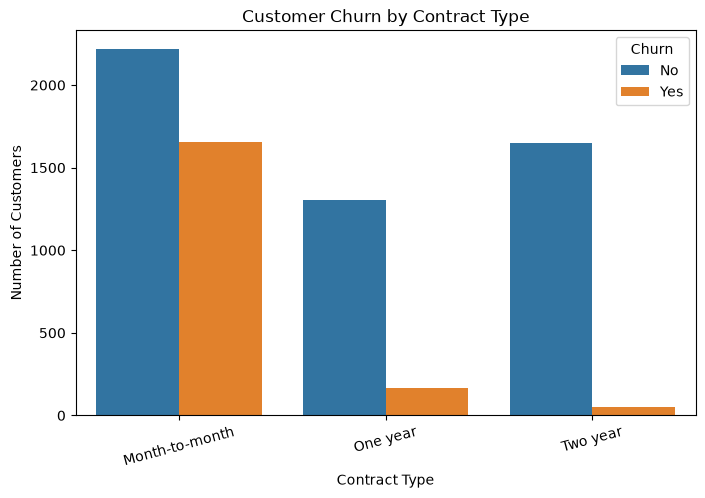

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

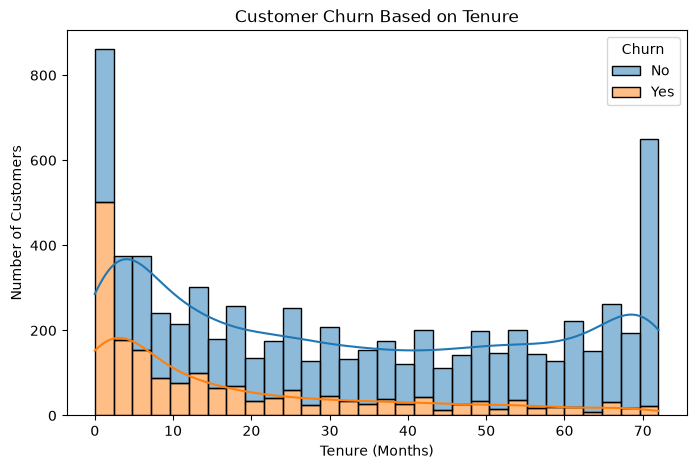

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True,
    multiple="stack"
)

plt.title("Customer Churn Based on Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")
plt.show()

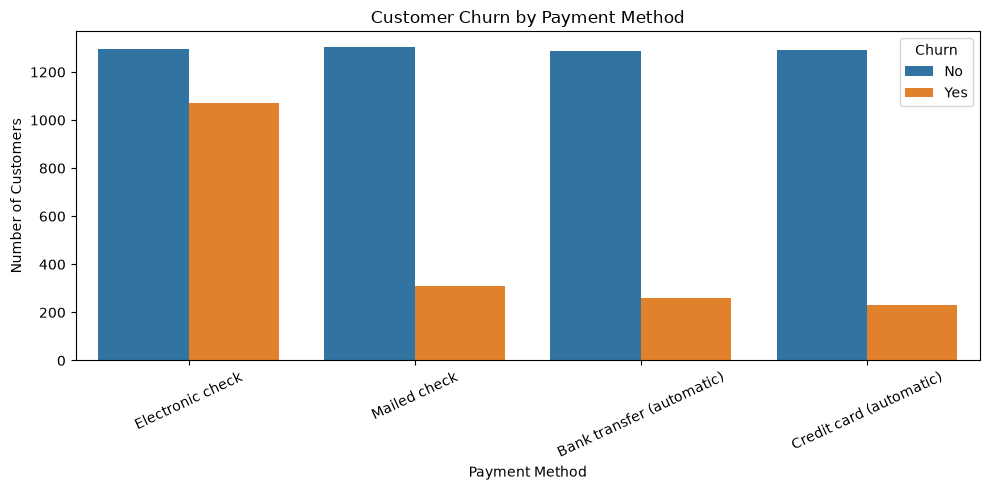

In [11]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

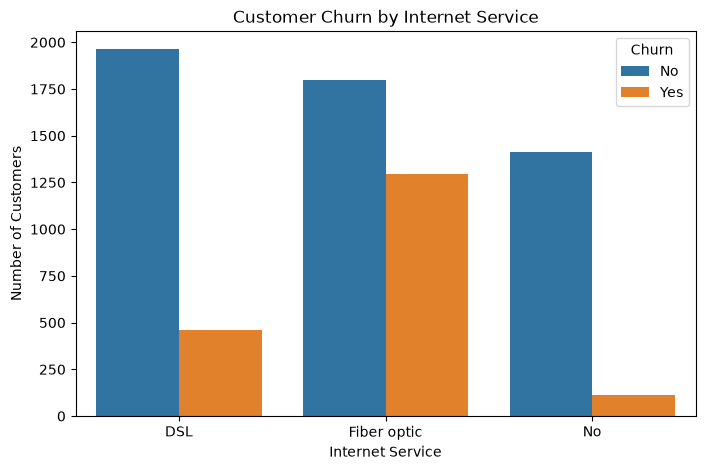

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Customer Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

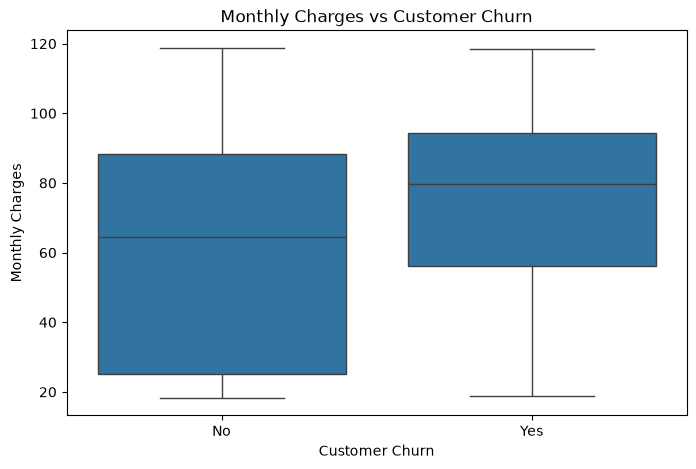

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [14]:
# Create a copy of the cleaned dataset
df_model = df.copy()

# Count the number of services used by each customer
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df_model["ServiceCount"] = df_model[service_columns].apply(
    lambda row: sum(value == "Yes" for value in row),
    axis=1
)

# Categorize customer tenure
df_model["TenureGroup"] = pd.cut(
    df_model["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "Medium", "Long", "Loyal"]
)

# Display new features
df_model[["tenure", "TenureGroup", "ServiceCount"]].head()

,tenure,TenureGroup,ServiceCount
0,1,New,1
1,34,Long,3
2,2,New,3
3,45,Long,3
4,2,New,1


In [15]:
# Remove customerID because it is only an identifier
X = df_model.drop(["Churn", "customerID"], axis=1)

# Target variable
y = df_model["Churn"].map({"Yes": 1, "No": 0})

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (7043, 21)
Target Shape: (7043,)


In [16]:
# Identify numerical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'ServiceCount']

Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


C:\Users\Admin\AppData\Local\Temp\ipykernel_5624\208387138.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 21)
Testing Data: (1409, 21)


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [19]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train model
logistic_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully.")

Logistic Regression Model Trained Successfully.


In [20]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully.")

Random Forest Model Trained Successfully.


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [25]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.7331,0.4983,0.7914,0.6116,0.8418
1,Random Forest,0.7693,0.5576,0.6337,0.5932,0.8212


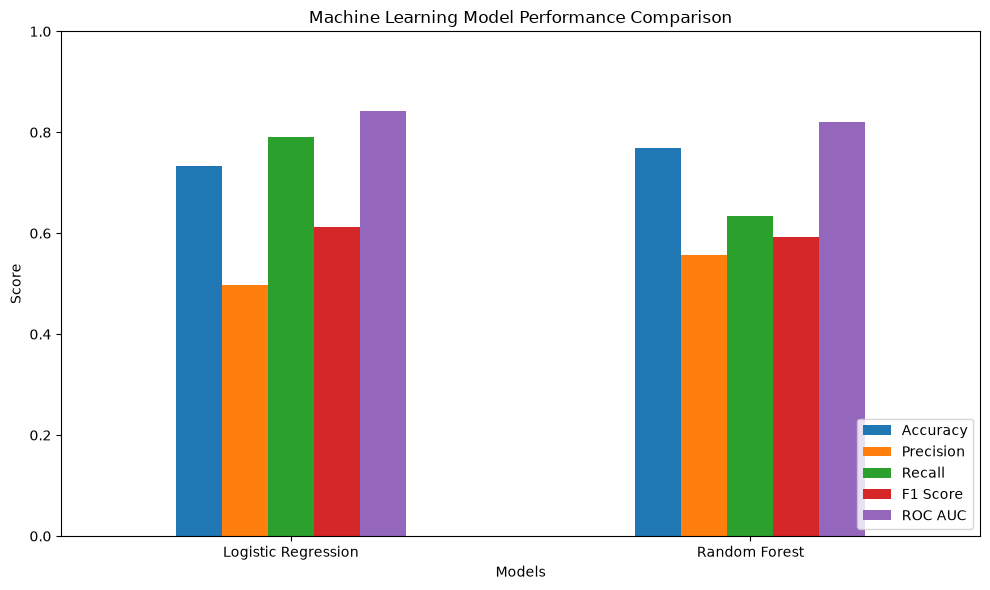

In [26]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [27]:
# Select the best model based on F1 score
best_model_name = results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

predictions = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Not Churned", "Churned"]
))

Best Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.90      0.71      0.80      1035
     Churned       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



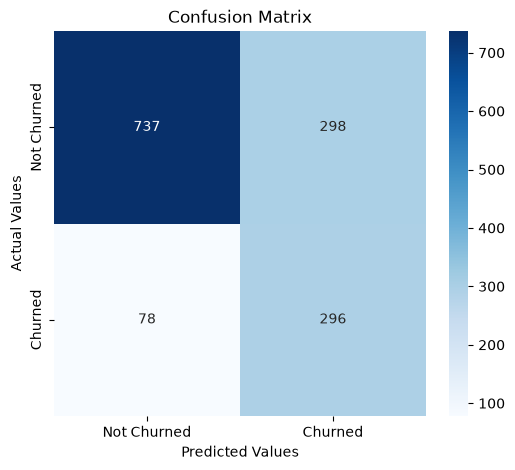

In [28]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Churned", "Churned"],
    yticklabels=["Not Churned", "Churned"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

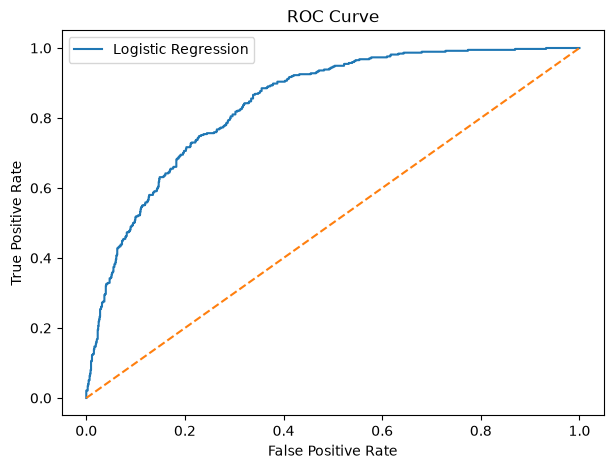

ROC AUC Score: 0.8418274819809347


In [29]:
from sklearn.metrics import roc_curve

probabilities = best_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, probabilities)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f"{best_model_name}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC AUC Score:", roc_auc_score(y_test, probabilities))

In [30]:
# Get the trained Random Forest model
rf_pipeline = random_forest_model

# Extract feature names after preprocessing
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance
importances = rf_pipeline.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                                Feature  Importance
3                     num__TotalCharges    0.125135
2                   num__MonthlyCharges    0.114034
1                           num__tenure    0.111876
37         cat__Contract_Month-to-month    0.065776
39               cat__Contract_Two year    0.035664
19               cat__OnlineSecurity_No    0.033600
28                  cat__TechSupport_No    0.031949
44  cat__PaymentMethod_Electronic check    0.030135
4                     num__ServiceCount    0.029001
17     cat__InternetService_Fiber optic    0.028368
49                 cat__TenureGroup_New    0.023853
22                 cat__OnlineBackup_No    0.016054
5                    cat__gender_Female    0.015930
6                      cat__gender_Male    0.015628
0                    num__SeniorCitizen    0.015524


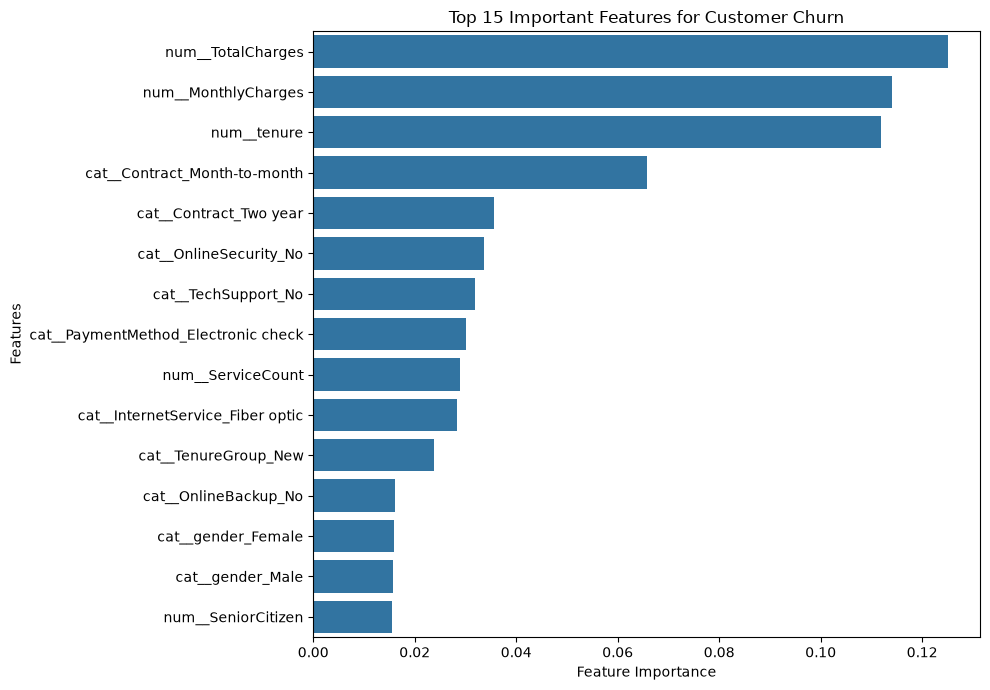

In [31]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [32]:
# Select one customer from the test dataset
sample_customer = X_test.iloc[[0]]

# Predict churn
prediction = best_model.predict(sample_customer)[0]

# Get churn probability
churn_probability = best_model.predict_proba(sample_customer)[0][1]

print("Customer Churn Prediction:")

if prediction == 1:
    print("Customer is likely to leave.")
else:
    print("Customer is likely to stay.")

print("Churn Probability:", round(churn_probability * 100, 2), "%")

Customer Churn Prediction:
Customer is likely to stay.
Churn Probability: 10.98 %


In [33]:
print("CUSTOMER RETENTION STRATEGIES")
print("-" * 40)

print("1. Offer discounts and loyalty benefits to new customers.")

print("2. Encourage customers to choose long-term contracts.")

print("3. Provide special offers to customers with high monthly charges.")

print("4. Improve customer support and service quality.")

print("5. Provide attractive plans to customers using month-to-month contracts.")

print("6. Monitor customers with a high predicted churn probability.")

CUSTOMER RETENTION STRATEGIES
----------------------------------------
1. Offer discounts and loyalty benefits to new customers.
2. Encourage customers to choose long-term contracts.
3. Provide special offers to customers with high monthly charges.
4. Improve customer support and service quality.
5. Provide attractive plans to customers using month-to-month contracts.
6. Monitor customers with a high predicted churn probability.


In [34]:
# Save cleaned dataset
df_model.to_csv(
    "../outputs/cleaned_churn_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [35]:
import joblib

joblib.dump(
    best_model,
    "../outputs/customer_churn_model.pkl"
)

print("Trained model saved successfully.")

Trained model saved successfully.


In [36]:
print("=" * 50)
print("CUSTOMER CHURN PREDICTION PROJECT SUMMARY")
print("=" * 50)

print("Total Customers:", len(df_model))

print("Customers Churned:", (df_model["Churn"] == "Yes").sum())

print("Customers Retained:", (df_model["Churn"] == "No").sum())

print("\nBest Model:", best_model_name)

print("Accuracy:", round(
    results_df.loc[
        results_df["Model"] == best_model_name,
        "Accuracy"
    ].iloc[0] * 100, 2
), "%")

print("F1 Score:", round(
    results_df.loc[
        results_df["Model"] == best_model_name,
        "F1 Score"
    ].iloc[0], 4
))

print("\nProject Completed Successfully!")

CUSTOMER CHURN PREDICTION PROJECT SUMMARY
Total Customers: 7043
Customers Churned: 1869
Customers Retained: 5174

Best Model: Logistic Regression
Accuracy: 73.31 %
F1 Score: 0.6116

Project Completed Successfully!
